# CM laser with alignment: CDB vs first tuned, the φ sine, and the K0s φ asymmetry
**Questions**
1. Where does the first tuned correction (K0s π⁺/π⁻ curvature bias +90 µm, CDB −87 µm) differ from the CDB:
   R dφ, dφ, dR (two-row clusters only), sagitta, offset, pointing?
2. Is the sine in φ real, and can an alignment fix it?
3. Is it related to the K0s φ asymmetry?

**Alignment used (local, ideal TPC coordinates, no tracking alignment):** the CM truth is aligned to the pad plane with
field off (78242): rigid S −2.03 mrad, (−0.61, +0.36) mm; N −2.94 mrad, (−0.34, +0.07) mm; plus the 36 pad-module
offsets (median RΔφ per module, ring mean removed) from the same run. Sector edges (±6°) excluded everywhere.

**What a TPC-only track keeps** of a distortion RΔφ(R) = a + bR + cR² over 30–76 cm: the R² curvature (sagitta), and its
**pointing**: the quadratic extrapolated to R = 0 (the sideways miss at the vertex). A constant dφ is a rotation (harmless).

In [1]:
%matplotlib inline
import os, sys
sys.path.insert(0, '/home/yoren/bnl/ROOT/install/lib')
import numpy as np, matplotlib.pyplot as plt
import cmplots as c, truthalign as ta, alignqa as aq, slidestyle
plt.rcParams['figure.dpi'] = 80
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 15, 'axes.labelsize': 15, 'legend.fontsize': 11,
                     'xtick.labelsize': 13, 'ytick.labelsize': 13, 'figure.titlesize': 16})
def show(*figs):
    for f in figs:
        display(slidestyle.restyle(f))
    plt.close('all')
ta.correct_truth()

{0: array([-2.02877286, -0.60458442,  0.35802086]),
 1: array([-2.9392519 , -0.34088598,  0.06488564])}

## 1. Alignment: pad-module offsets from field off
Median RΔφ per pad module (3 rings × 12 sectors) vs the rigidly aligned truth, field off 78242: subtracted from every
"vs truth" comparison below.

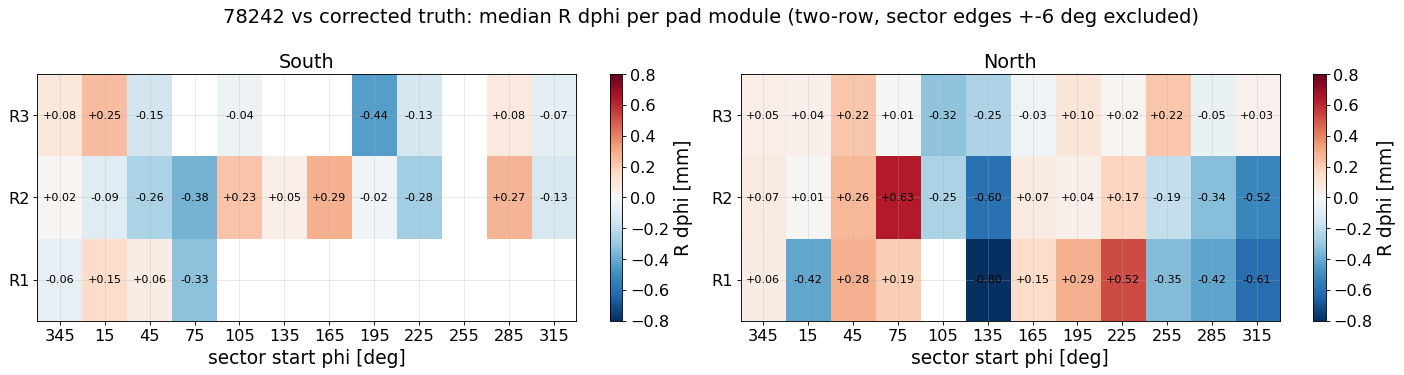

In [2]:
show(ta.fig_module_map())

## 2. CDB and first tuned vs the aligned truth, vs R (795xx)
RΔφ and dφ: all matched clusters; dR: **balanced two-row clusters only** (one-row CM clusters saturate in R).
Legend: decomposition of RΔφ(R) – offset at 52 cm, slope, free R² sagitta, pointing at R = 0.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/alignqa.py:65: RuntimeWarning: Mean of empty slice
  return np.nanmean(P, axis=0)
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/alignqa.py:76: RuntimeWarning: Mean of empty slice
  return np.nanmean(P, axis=0) if P else np.full(len(ta.PRC), np.nan)


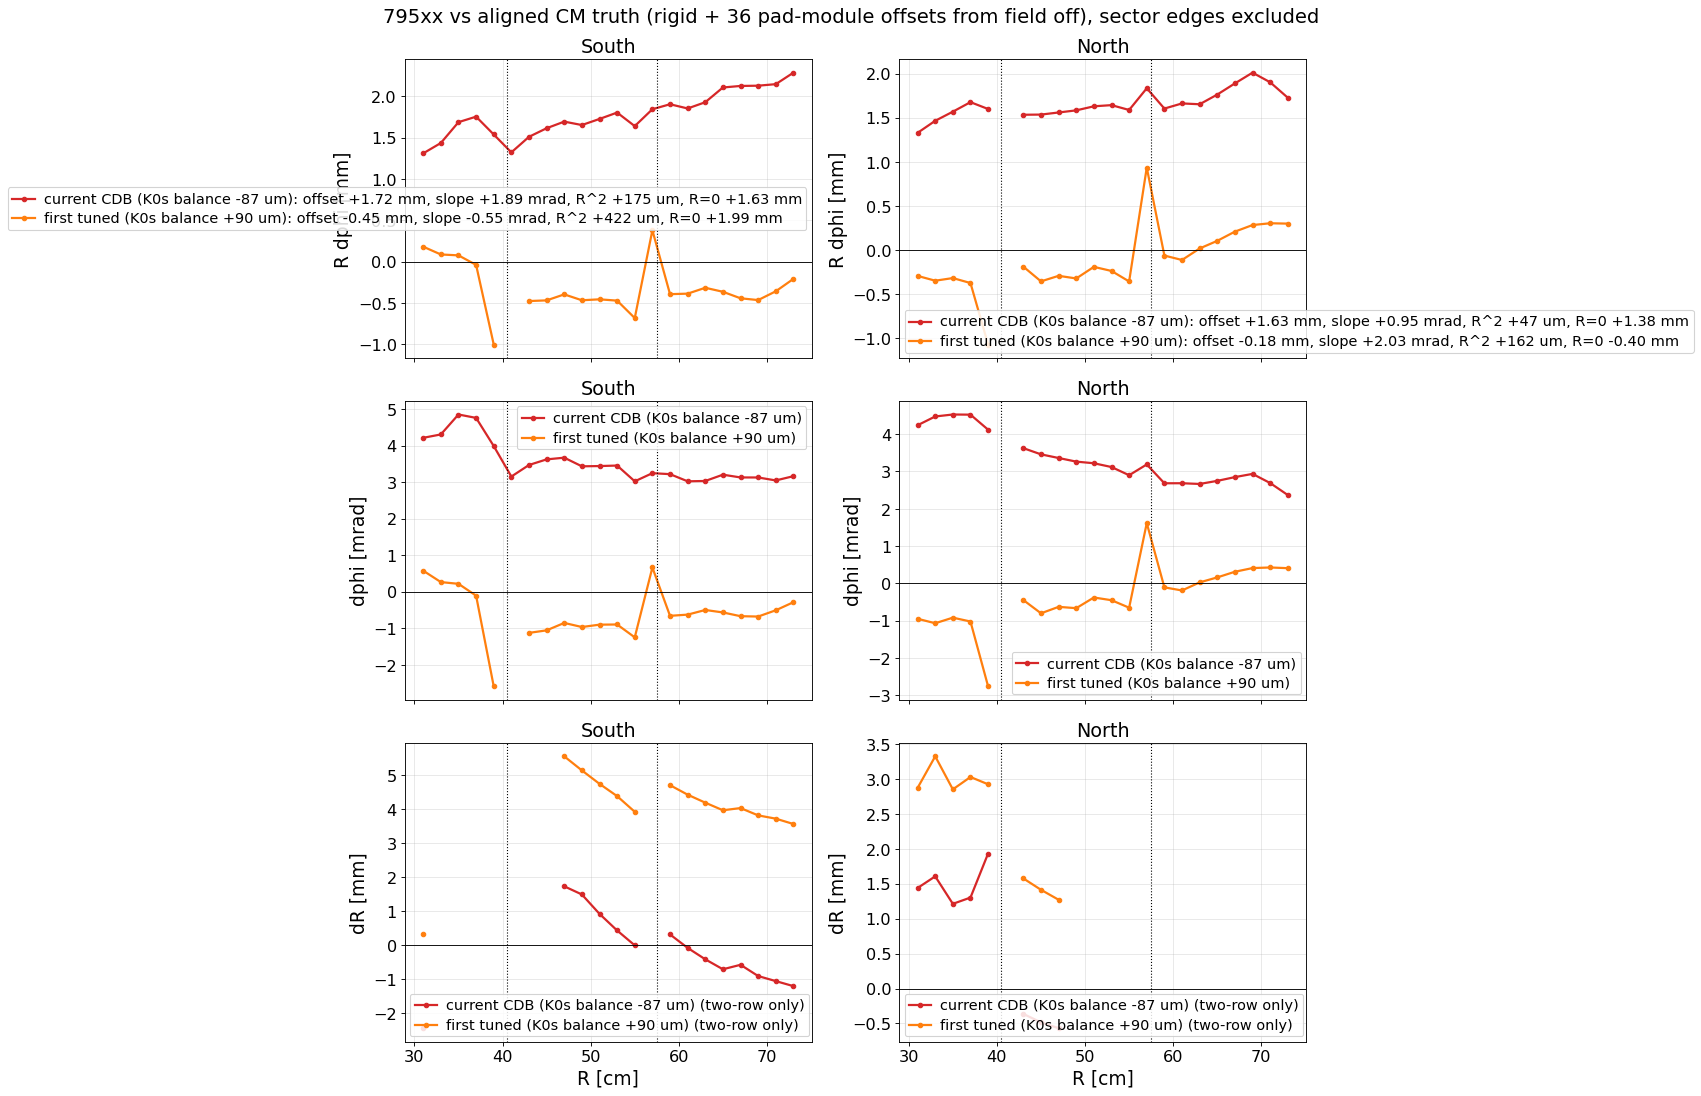

In [3]:
show(aq.fig_truth_R())

## 3. First tuned − CDB on the same clusters (no truth, no alignment)
The difference of the two corrections on identical input clusters: exact, no truth or matching involved.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/truthalign.py:1704: RuntimeWarning: Mean of empty slice
  return np.nanmean(P, axis=0) if P else np.full(len(PRC), np.nan)


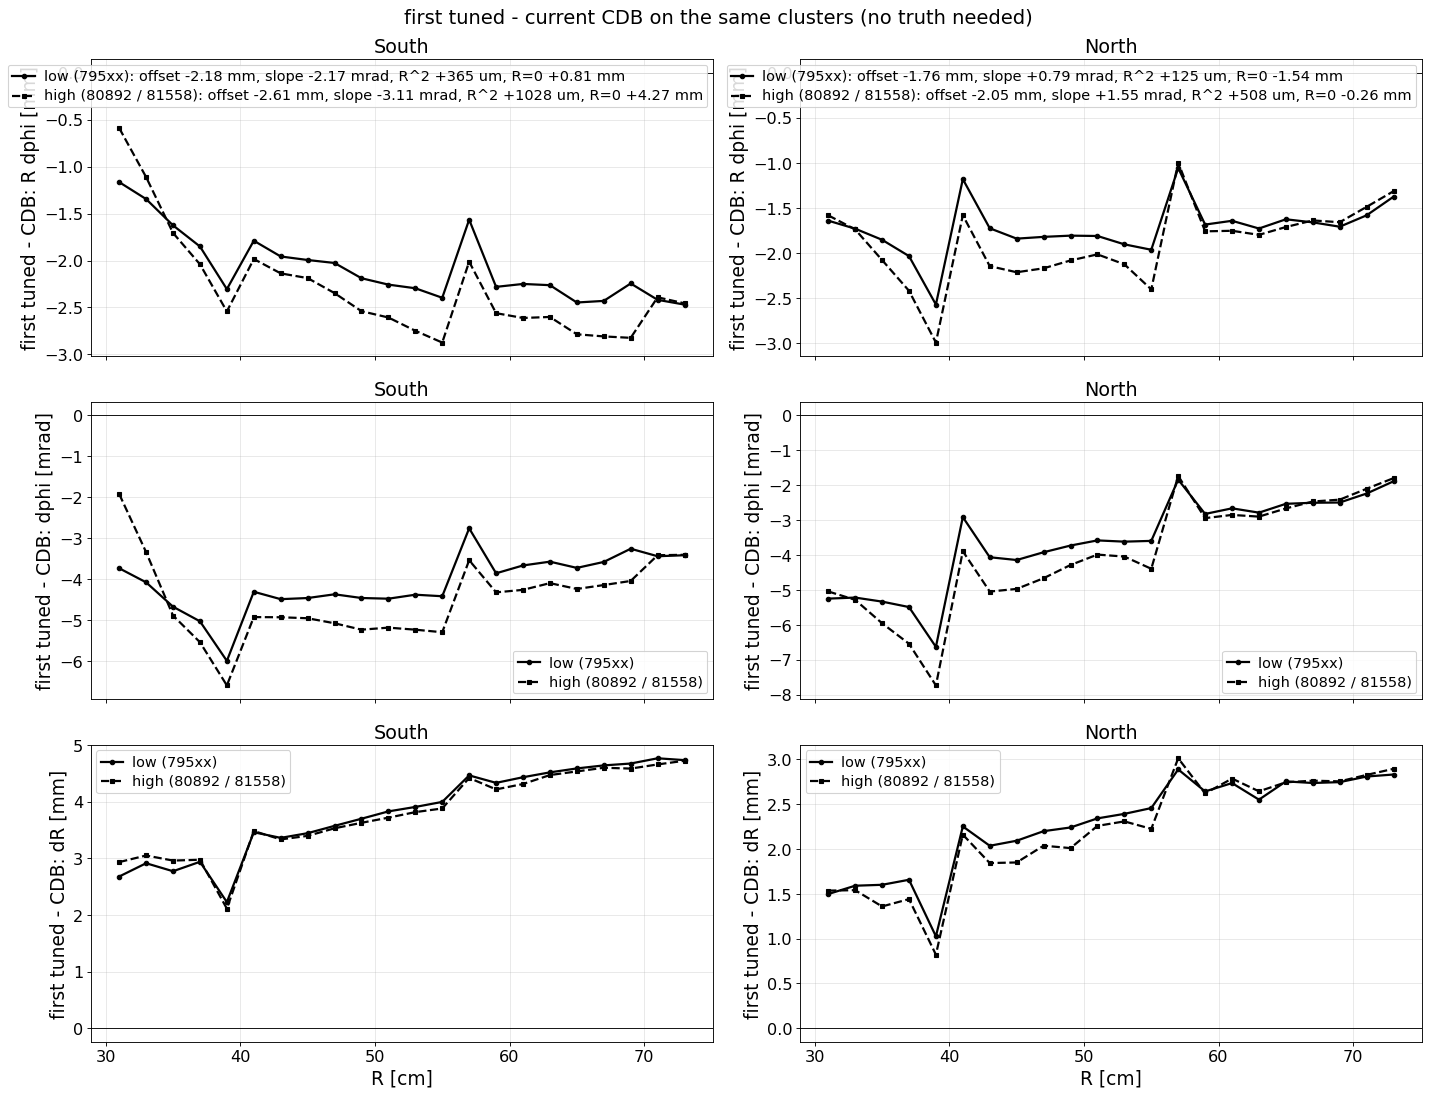

In [4]:
show(aq.fig_paired_R())

**Reading.** At 795xx the first tuned correction differs from the CDB by
- a flat offset ≈ −2 mm (both sides): a sideways shift of all tracks (DCA, V0 vertex), not the curvature;
- a slope (constant dφ: B$_r$ 0.8 → rotation), harmless for tracks;
- **R² curvature +365 µm (S) / +125 µm (N)**: the part TPC-only tracks keep. K0s: +177 µm (−87 → +90), ratio ≈ 0.7;
- steps at the module boundaries (40.5, 57.5 cm: frames −180 → 0) of 0.5–1 mm, which also enter the track fit;
- dR: +3 to +4.5 mm (S), +1.5 to +2.8 mm (N) – large, smooth.

## 4. Per 30° sector: offset, sagitta, pointing, slope
Red / orange: each correction vs the aligned truth. Black dashed: first tuned − CDB on the same clusters.

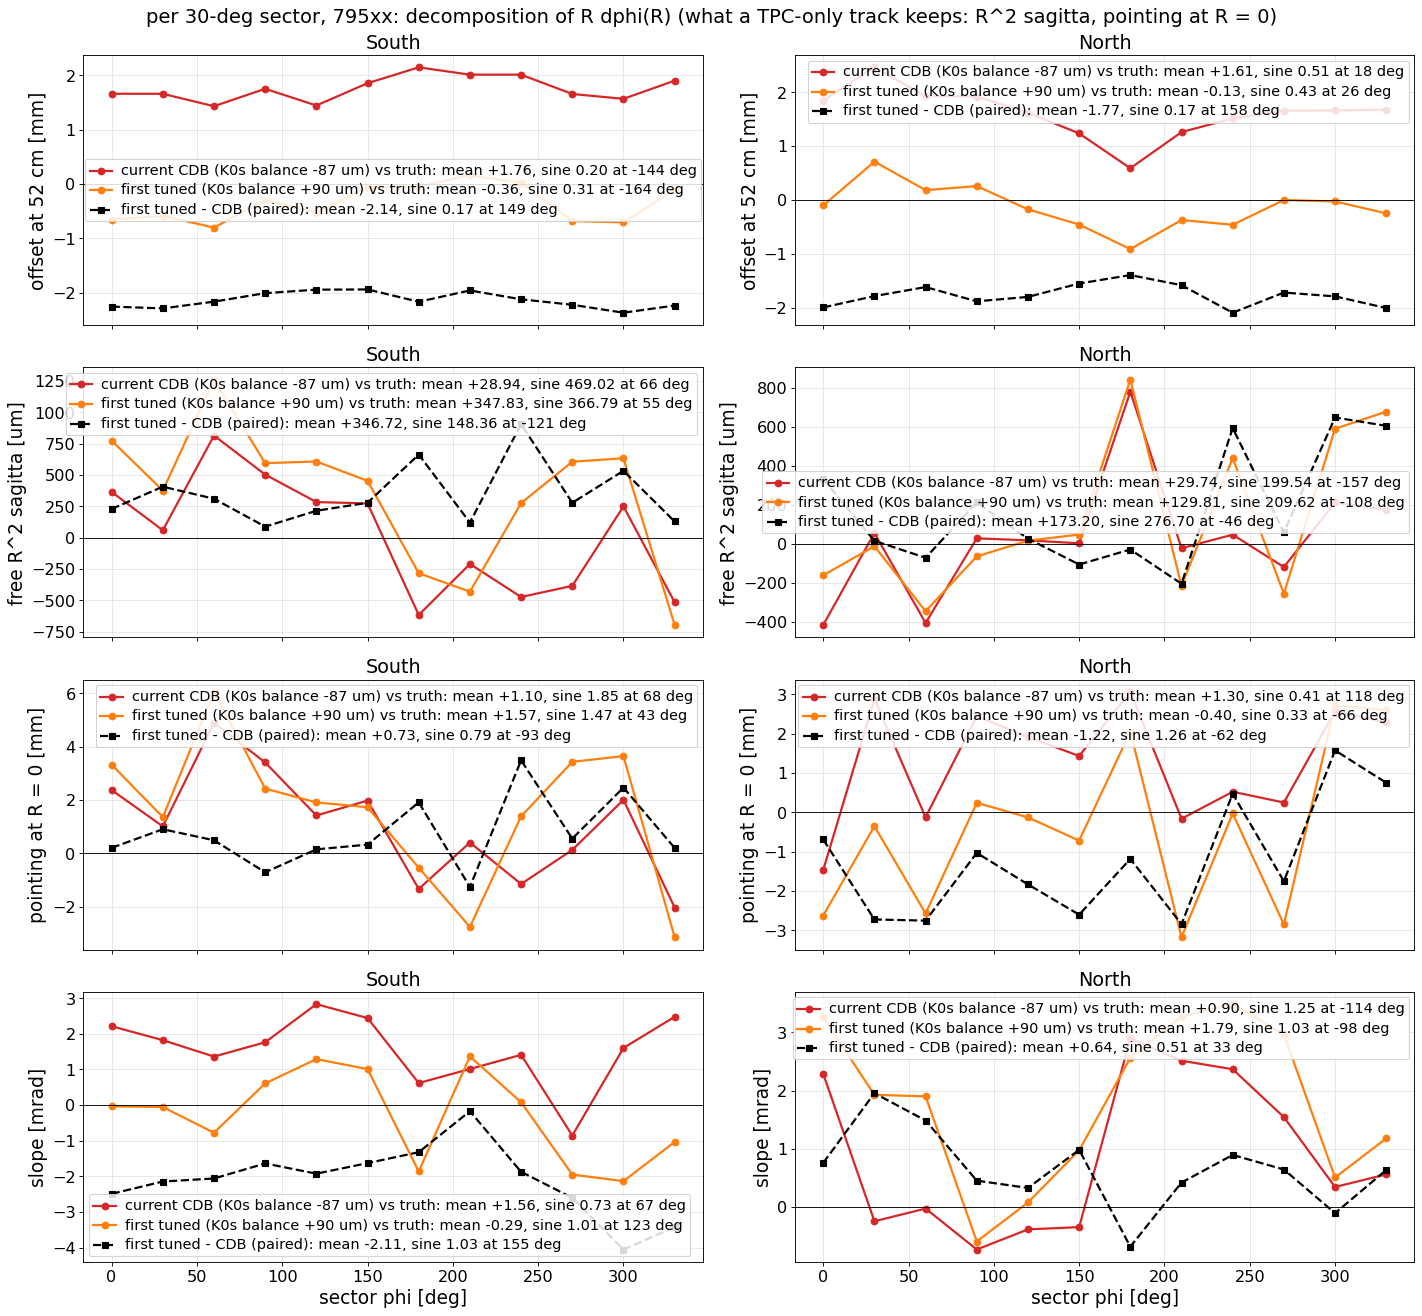

In [5]:
show(aq.fig_sectors())

**Reading.** Both corrections have a **first harmonic in the R² sagitta** (South ≈ 370–470 µm at ≈ 60°) and therefore in
the pointing at R = 0 (≈ 1.5–1.9 mm). The paired difference has a much smaller sine: the sine is common to both, i.e. it
is not something either correction puts in, it is something neither removes.

## 5. Is the sine real? TPC-only tracks see it
Single TPC-only tracks, 79513, CDB (tau fit): rDCA$_\mathrm{zero}$ is measured to the vertex (1.58, 2.85) mm. Per charge
the signed DCA changes sign; the charge-odd part (q⁺ − q⁻)/2 is the sideways miss common to all tracks at that φ.

Welcome to JupyROOT 6.30/06


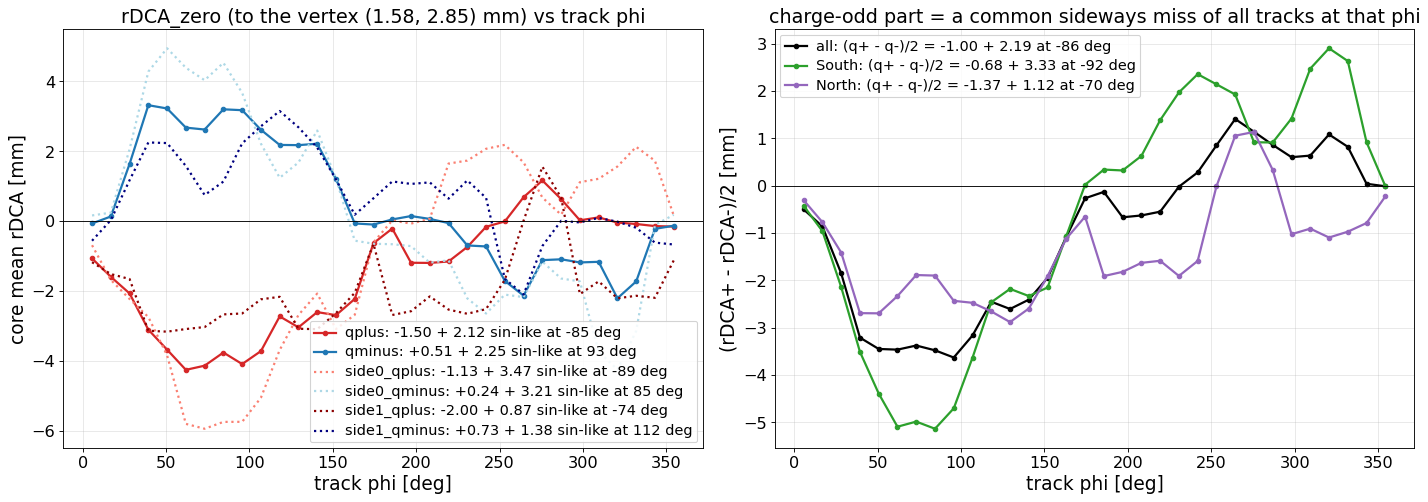

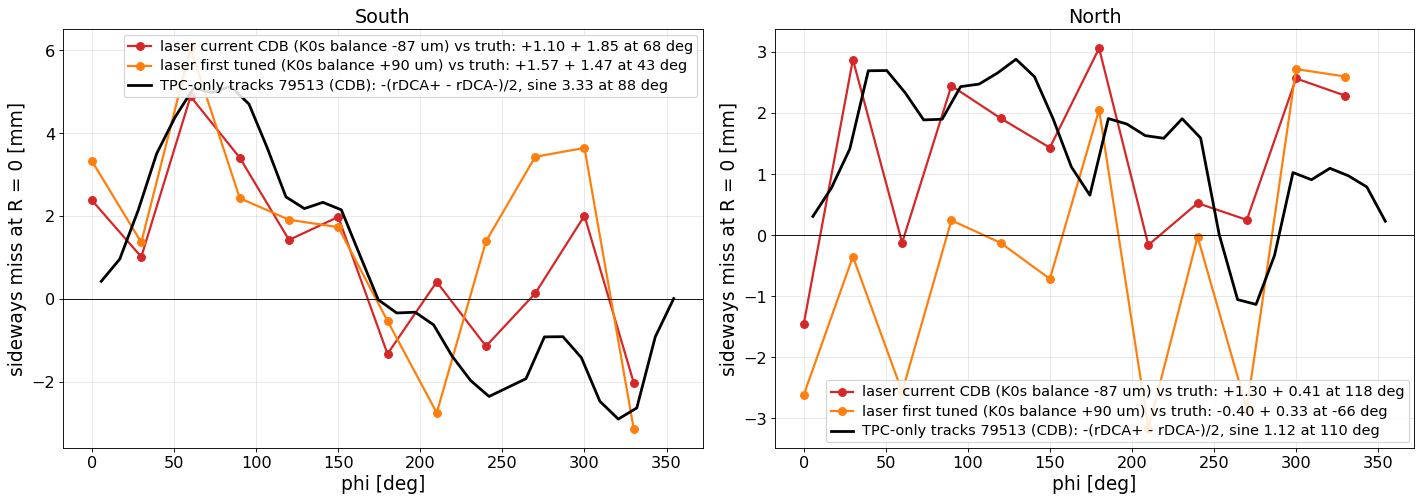

In [6]:
show(aq.fig_track_dca())
show(aq.fig_pointing_vs_tracks())

**Reading.**
- Tracks miss sideways by **−0.7 + 3.3 sin-like at ≈ 90° (South)** and −1.4 + 1.1 at ≈ 110° (North): different on the
  two sides, so it is **not the beam position** (that would be common to both).
- The laser predicts the same thing: the CDB pointing at R = 0 per sector (vs the aligned truth) follows the track miss
  in South almost point by point (+5 mm at 60–100°, −2 mm at 200–330°); North agrees in phase, with a smaller amplitude.
  (The rDCA sign convention is not tied to the laser RΔφ sign: the track curve is shown with the sign that matches.)

## 6. Where does the sine come from? (careful: second-order effect)
**Caution.** In dφ averaged over R (the slide plot), beam − no beam is flat in φ on both sides: the offset sine of
beam − no beam is only 0.15–0.2 mm (low lumi). The large sine in beam vs truth on that slide was in the **static**
(field off vs truth has it) and came from the CM-truth rigid offset, now removed by the alignment.
What is left is a sector-dependent **R shape** (curvature), ±0.3–0.5 mm over 30–76 cm, which the extrapolation to R = 0
amplifies. Below: RΔφ(R) per sector minus the mean over sectors.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/alignqa.py:415: RuntimeWarning: Mean of empty slice
  LO = np.nanmean([_secprof(r, ta.v4_tag(k, tag), s) for r, k in blocks(LOW)], axis=0)
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/alignqa.py:416: RuntimeWarning: Mean of empty slice
  HI = np.nanmean([_secprof(r, ta.v4_tag(k, tag), s) for r, k in blocks(('80892', '81558'))], axis=0)


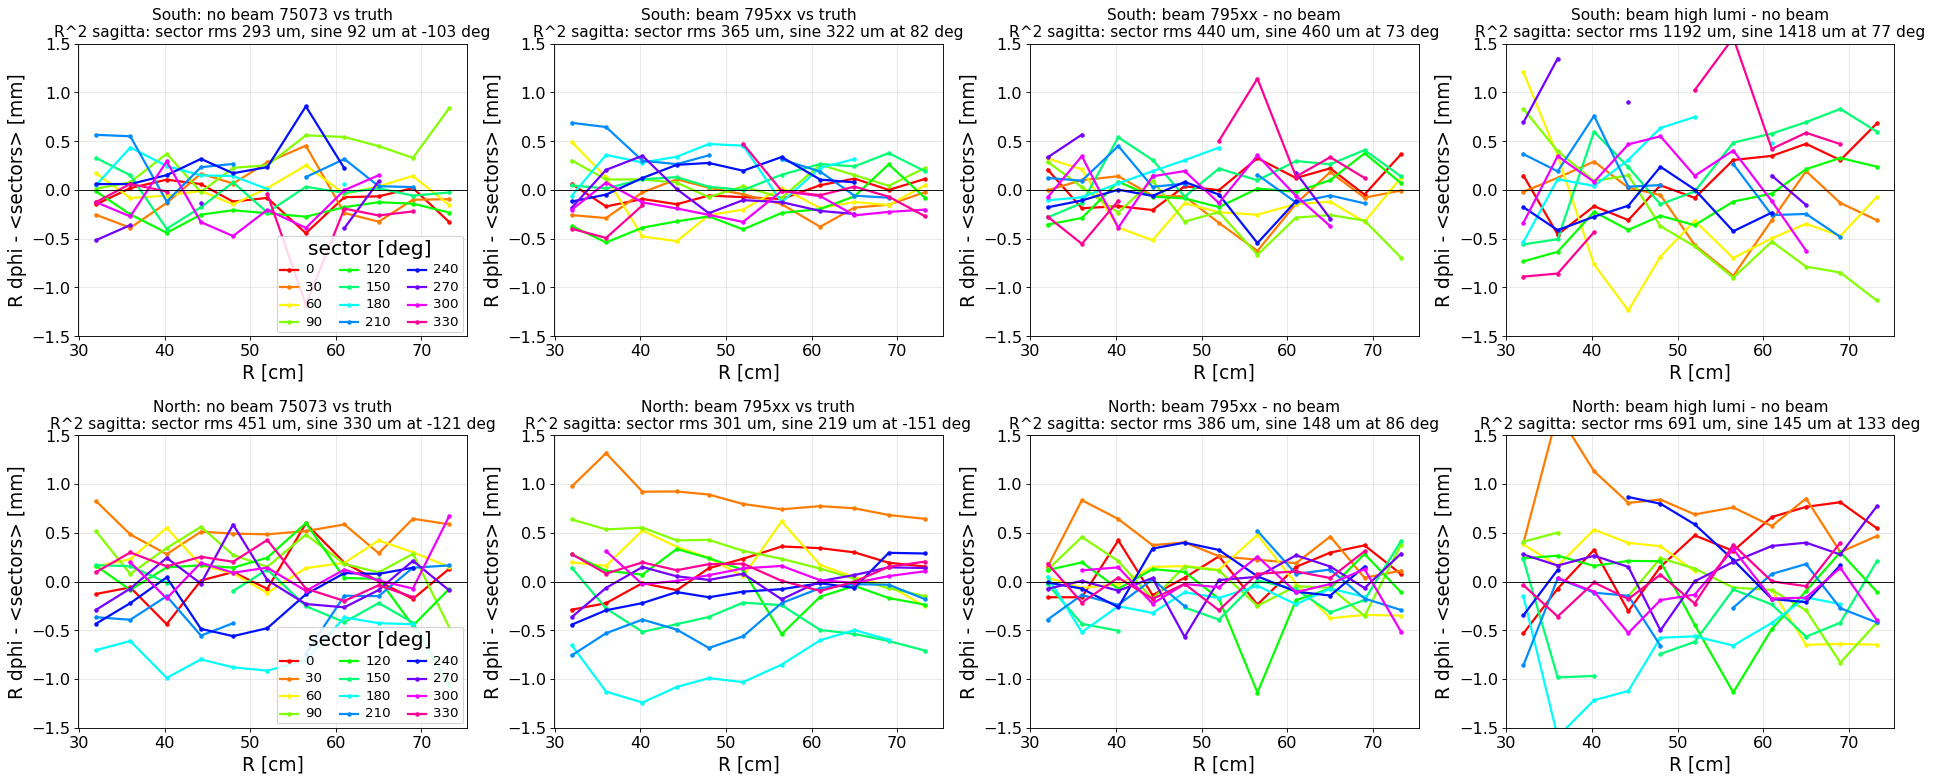

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/alignqa.py:107: RuntimeWarning: Mean of empty slice
  return np.nanmean(V, axis=0)


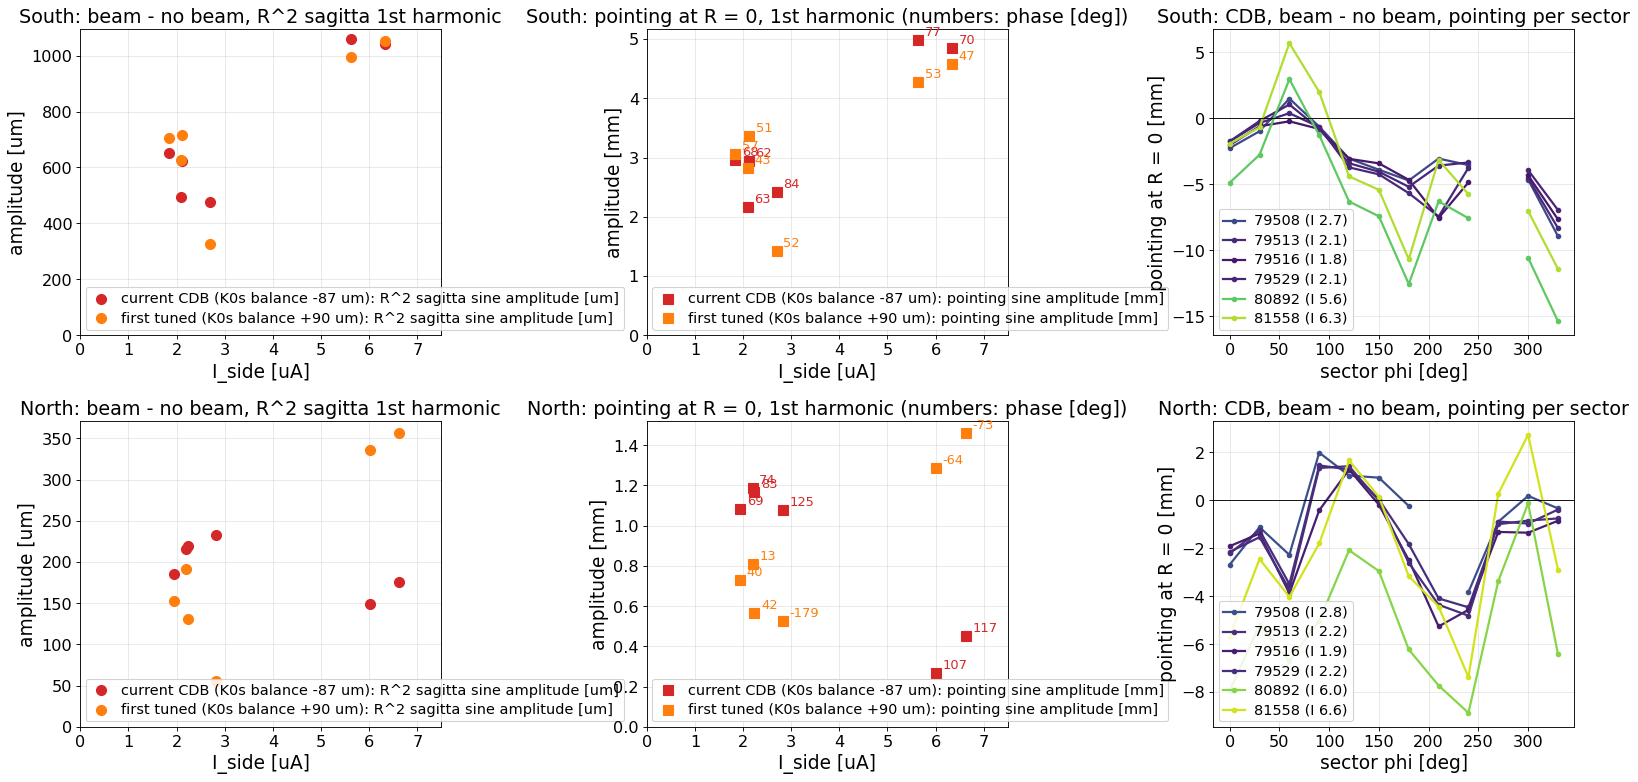

In [7]:
show(aq.fig_sector_check())
show(aq.fig_sine_lumi())

**Reading.**
- No beam: sector-to-sector R² scatter 290–450 µm rms (static + noise), no stable phase (75073 vs 83319 differ).
- South, beam − no beam: R² sine 460 µm at ≈ 73° (low lumi) → ≈ 1400 µm at ≈ 77° (high lumi); high − low has the same
  phase (62°). This one grows with luminosity and keeps its phase: **a South φ-dependent space-charge shape is likely,
  but at low lumi it is the same size as the static sector scatter**; the high-lumi CM data have gaps.
- North: no stable sine (phase jumps between references and luminosities).
- The tracks at 79513 have a larger South sine (3.3 mm) than the laser predicts at low lumi (1.2–2 mm): the laser does
  not explain all of it.

**Decisive checks (cheap):** the same track rDCA vs φ at high luminosity (80892 / 81558): if the South sine grows ~×2–3,
it is space charge; if not, it is static / something else. And the K0s φ asymmetry at high luminosity.

## 7. K0s φ asymmetry (current CDB, v0_topology_qa)
Gaus + pol2 fit per φ slice: yield, mass, width.

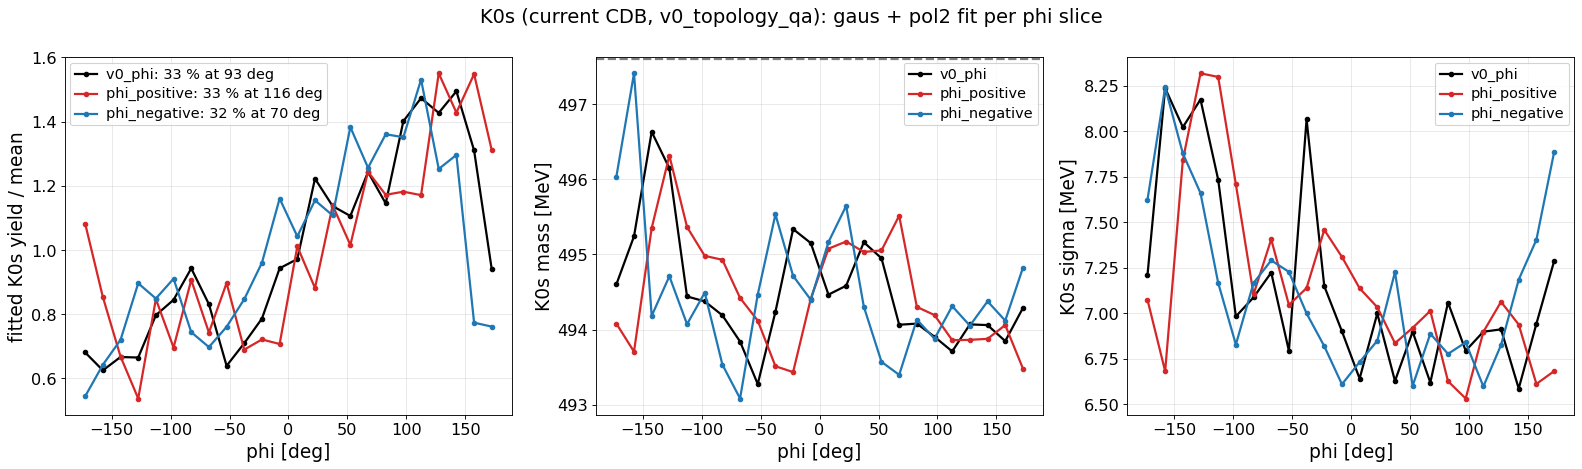

  decay R [cm]             sample         N  1st harmonic  phase
     2 -     3   peak - sidebands      9372         53.4%     95
     2 -     3          sidebands     26402         59.4%     94
     3 -     4   peak - sidebands     23437         45.9%     93
     3 -     4          sidebands     31043         47.4%     91
     4 -     5   peak - sidebands     25853         40.9%     91
     4 -     5          sidebands     18027         44.6%     88
     5 -     7   peak - sidebands     38094         40.6%     92
     5 -     7          sidebands     16122         42.2%     83
     7 -    10   peak - sidebands     45978         38.6%     90
     7 -    10          sidebands     18198         37.3%     92
    10 -    15   peak - sidebands     55384         36.1%     91
    10 -    15          sidebands     22028         34.4%     89
    15 -    25   peak - sidebands     38982         34.6%     89
    15 -    25          sidebands     21195         30.3%     96
    25 -    40   peak - s

In [8]:
show(aq.fig_k0s_phi())
print(f"{'decay R [cm]':>14s} {'sample':>18s} {'N':>9s} {'1st harmonic':>13s} {'phase':>6s}")
for lo, hi, nm, n, a, p in aq.k0s_harm_vs_radius():
    print(f"{lo:6.0f} - {hi:5.0f} {nm:>18s} {n:9.0f} {a:12.1f}% {p:6.0f}")

**Reading.**
- The fitted K0s **yield** has a 33 % first harmonic at **+93°**; the mass moves by only ±0.3 MeV (first harmonic) – the
  asymmetry is not a mass shift out of a window. The width is worse (8 MeV) at −160 … −110°.
- The same harmonic (35–45 % at ≈ 90°) is in the sidebands, Λ and anti-Λ, at every decay radius (2–40 cm): it is a
  **pair-level** effect of the V0 finding, not K0s physics; single tracks show only 4 %.
- Displaced single tracks (|rDCA| 0.3–3 cm) do show 20–30 % at ≈ 80–90°: tracks heading +y are pushed to larger DCA –
  the same φ where the sideways miss (Section 5) is largest.
- Not explained by the decay-radius / DIRA cuts being taken from (0,0,0) instead of the beam: that would fade with decay
  radius, and it does not.

**Hypothesis to test:** a φ-dependent distortion (Section 6) gives tracks a φ-dependent sideways miss (±3 mm) and
curvature error (±5 % at 1 GeV in South), and that modulates the V0 finding efficiency.

## 7b. The CM → pad-plane alignment from field off, and why "better to the CM" made tracks worse
With field off there is no E×B: the RΔφ of field off vs the rigidly aligned truth is CM → pad-plane geometry. The rigid
fit (rotation, x, y) plus the 36 module offsets with their ring means removed leave an **R shape** (φ-averaged, weighted
with the K0s-candidate φ distribution):

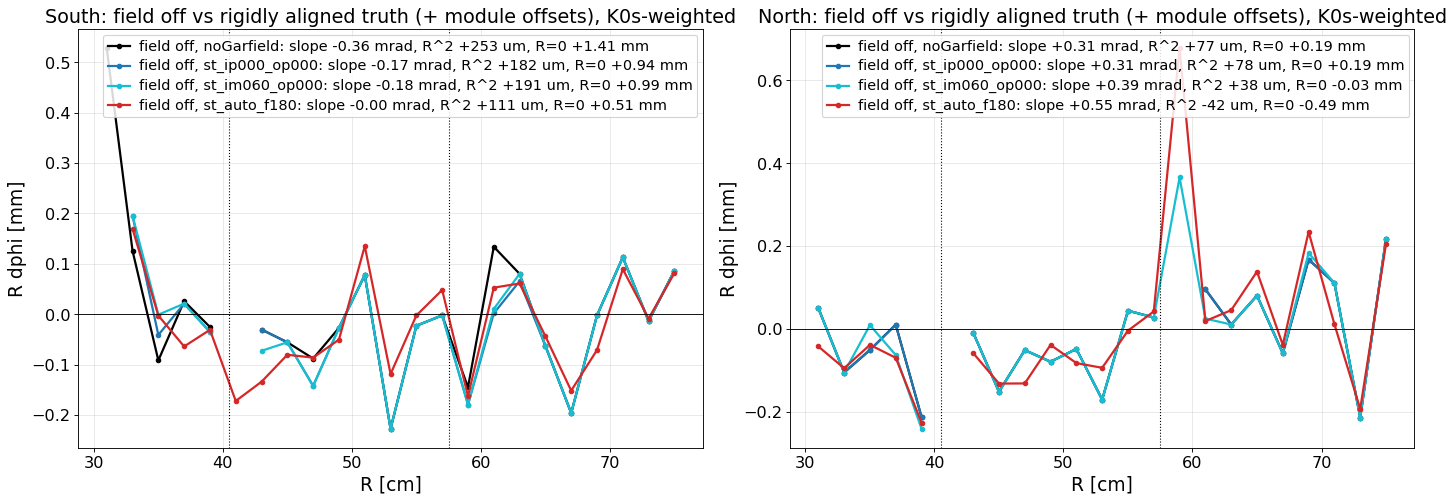

In [9]:
show(aq.fig_zf_alignment())

**South +110 … +250 µm, North −40 … +80 µm of R² sagitta** (the range = which field-off correction is used). This shape
was in our "truth", so every correction tuned to the truth inherited it. Below: the K0s balance of each correction vs its
laser R² sagitta, with the rigid alignment and with the **full field-off map** (sector × R) subtracted as alignment.

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/alignqa.py:486: RuntimeWarning: Mean of empty slice
  return dec(np.nanmean([wprof(x) for x in xs], axis=0), ta.PRC)


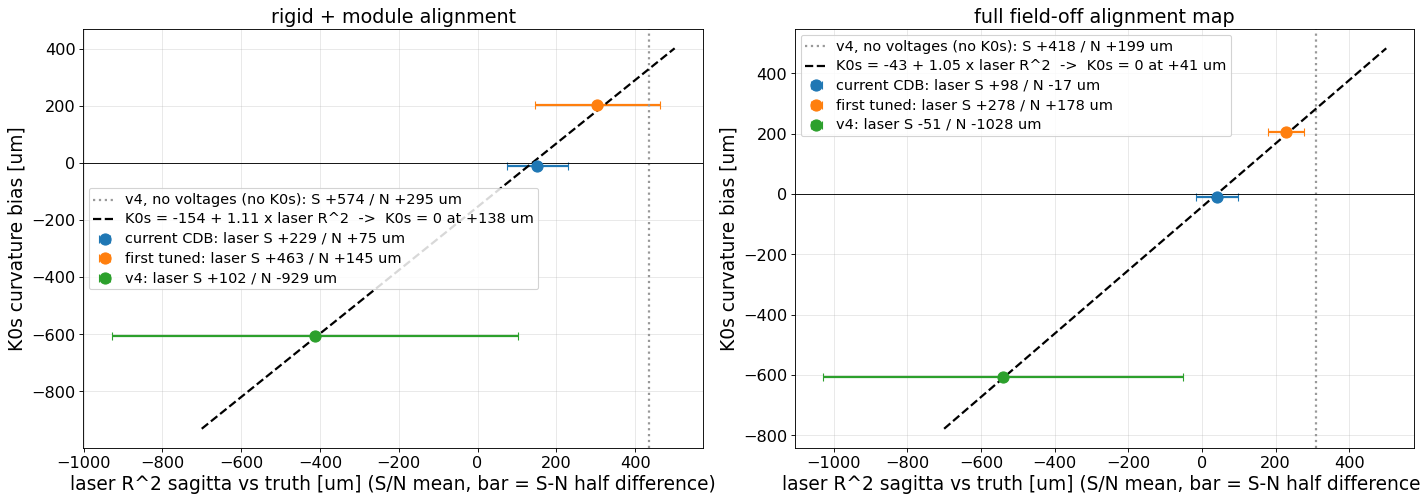

current CDB      S: offset +1.72 mm, slope +2.01 mrad, R^2   +98 um, pointing +1.18 mm (full alignment, K0s-weighted)
current CDB      N: offset +1.69 mm, slope +0.28 mrad, R^2   -17 um, pointing +1.46 mm (full alignment, K0s-weighted)
first tuned      S: offset -0.43 mm, slope -0.25 mrad, R^2  +278 um, pointing +1.12 mm (full alignment, K0s-weighted)
first tuned      N: offset -0.13 mm, slope +1.46 mrad, R^2  +178 um, pointing +0.02 mm (full alignment, K0s-weighted)
v4               S: offset -0.16 mm, slope +0.18 mrad, R^2   -51 um, pointing -0.52 mm (full alignment, K0s-weighted)
v4               N: offset +0.40 mm, slope +0.38 mrad, R^2 -1028 um, pointing -5.05 mm (full alignment, K0s-weighted)
v4, no voltages  S: offset +0.50 mm, slope -0.53 mrad, R^2  +418 um, pointing +2.91 mm (full alignment, K0s-weighted)
v4, no voltages  N: offset +2.07 mm, slope +1.33 mrad, R^2  +199 um, pointing +2.39 mm (full alignment, K0s-weighted)
no beam 75073 CDB static S: offset +1.65, slope +0.45, R

In [10]:
show(aq.fig_k0s_calibration())
for tag, lab in aq.MODEL_LAB.items():
    for s in (0, 1):
        o, sl, r2, a0, vc = aq.model_R2(tag, s, True)
        print(f"{lab:16s} {'SN'[s]}: offset {o:+.2f} mm, slope {sl:+.2f} mrad, R^2 {r2:+5.0f} um, pointing {a0:+.2f} mm (full alignment, K0s-weighted)")
for run in ('75073', '83319'):
    for s in (0, 1):
        o, sl, r2, a0, vc = aq.dec(aq.wprof(aq.full_aligned(run, 'cdb_st', s)), ta.PRC)
        print(f"no beam {run} CDB static {'SN'[s]}: offset {o:+.2f}, slope {sl:+.2f}, R^2 {r2:+5.0f} um, pointing {a0:+.2f}")

**Reading.**
- K0s balance from the same estimator and mass window for every correction (CDB −10, first tuned +204, v4 −608 µm).
  With the full field-off alignment the three corrections lie on **K0s = −43 + 1.05 × laser R²** (residuals ≤ 10 µm):
  slope 1 as it should be, zero at +41 µm, within the field-off systematic (±70 µm). With the rigid alignment only the
  zero is at +138 µm: **the field-off alignment is what made the CM and the tracks disagree.**
- A 17 % N⁻/N⁺ difference at 2 GeV (first tuned vs CDB) is ≈ 210 µm of sagitta (falling spectrum), not 500 µm.
- The full field-off map also removes most of the φ sine (CDB South pointing 1.85 → 0.55 mm): **the sine is mainly
  CM → pad alignment**.
- The two no-beam runs disagree (North R² +245 vs +590 µm, different sines): the static reference changes with time,
  so "beam − no beam" mixes space charge with a time-dependent alignment.

**Procedure (proposal):** CM truth → pad plane = rigid + full field-off map (verified: field off itself then flat) +
(if needed) a residual field-on R² term per side fixed by the K0s balance per side (≈ 40 µm on average now). Then tune the static model and the space charge to that truth, and check with the no-beam runs **taken
close in time** to the beam runs.

## 8. Summary and next steps
1. **First tuned vs CDB**: the K0s difference follows the R² curvature (+365 / +125 µm); in addition a −2 mm flat
   offset, a rotation and module-boundary steps. The per-sector shape is similar for both.
2. **The sine is in the tracks** (South 3.3 mm, North 1.1 mm sideways miss); the laser CDB pointing per sector has the
   same South shape, at about half the amplitude.
3. **Not in dφ itself**: beam − no beam is flat in φ in the R-averaged dφ. The laser sine is a sector-dependent curvature
   (R shape); in South it grows with luminosity with a stable phase (likely space charge), but at low lumi it is at the
   level of the static sector scatter. North: no stable effect. **Not established yet.**
4. **Next**: (0) track rDCA vs φ and the K0s φ asymmetry at high luminosity (decisive); (a) per-module GEM currents (TPC_CONDITIONS) → a φ-dependent keff (South) or a φ-dependent map, test on the
   laser (beam − no beam sine must vanish); (b) run StudyV0TopologyQA on the corrected V0 outputs (first tuned, v4, B):
   if the K0s φ asymmetry changes with the correction, it is the distortion; (c) put the V0 decay radius / DIRA on the
   beam position, not (0,0,0).